# Test de las seis redes recuperadas

Se evalúan los seis modelos exactos de la captura: RNN, LSTM y GRU con niveles y señales, semilla 42. Son los pesos y escalas ajustados hasta 2017, sin reentrenamiento, promedio de semillas ni mezcla con el ingenuo. La época de esos pesos se eligió con validación 2018–2022.

Este bloque 2023–2024 ya se había evaluado con otra versión del modelo; aquí se realiza una comparación adicional de seis redes recuperadas.

Este notebook lee resultados guardados: no entrena ni modifica modelos. El ratio 1 corresponde al ingenuo spot; menor que 1 significa menor RMSE en ese bloque, no rentabilidad.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, display
ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
REPORT = ROOT / 'experiments/recovered_fixed_test_20261120/report'
display(pd.read_csv(REPORT / 'ratios_validation_test.csv').round(4))
display(pd.read_csv(REPORT / 'comparison_wide.csv').round(4))

,architecture,variant,seed,validation_5,validation_63,validation_252,test_5,test_63,test_252
0,RNN,levels,42,0.9997,0.9721,0.7805,1.0661,1.3880,1.4339
1,RNN,signals,42,0.8682,0.9323,0.8187,0.8856,0.9996,1.0046
2,LSTM,levels,42,0.9957,0.9731,0.8820,1.0032,1.0321,1.0567
3,LSTM,signals,42,1.0018,0.9516,0.8012,1.0234,1.1329,1.4475
4,GRU,levels,42,1.0033,0.9333,0.7053,1.0508,1.2549,1.3835
5,GRU,signals,42,0.8832,0.8789,0.7752,0.8977,1.1691,1.5363


,architecture,variant,seed,horizon,n,mae,mse,rmse,r2,relative_rmse,...,interval_mean_width,validation_n,validation_mae,validation_mse,validation_rmse,validation_r2,validation_relative_rmse,validation_relative_rmse_vs_future,validation_naive_rmse,validation_future_rmse
0,RNN,levels,42,5,499,3.6737,21.9499,4.6851,0.3600,1.0661,...,12.6261,1263,3.9630,32.4983,5.7007,0.9274,0.9997,1.1865,5.7026,4.8046
1,RNN,levels,42,63,441,11.1630,160.9460,12.6864,-3.3847,1.3880,...,29.3893,1205,10.6136,241.4954,15.5401,0.4844,0.9721,1.0479,15.9869,14.8302
2,RNN,levels,42,252,258,11.2217,182.6680,13.5155,-5.3758,1.4339,...,60.1439,1020,17.3099,463.3026,21.5245,0.1471,0.7805,0.7992,27.5774,26.9333
3,RNN,signals,42,5,499,3.1266,15.1453,3.8917,0.5584,0.8856,...,10.2275,1263,3.4668,24.5104,4.9508,0.9452,0.8682,1.0304,5.7026,4.8046
4,RNN,signals,42,63,441,7.5916,83.4733,9.1364,-1.2741,0.9996,...,32.7709,1205,10.5996,222.1615,14.9051,0.5257,0.9323,1.0050,15.9869,14.8302
5,RNN,signals,42,252,258,7.7594,89.6678,9.4693,-2.1297,1.0046,...,57.7197,1020,19.0725,509.7638,22.5779,0.0615,0.8187,0.8383,27.5774,26.9333
6,LSTM,levels,42,5,499,3.4558,19.4368,4.4087,0.4333,1.0032,...,12.3823,1263,3.9895,32.2395,5.6780,0.9280,0.9957,1.1818,5.7026,4.8046
7,LSTM,levels,42,63,441,7.9972,88.9778,9.4328,-1.4241,1.0321,...,32.4565,1205,11.1800,242.0334,15.5574,0.4833,0.9731,1.0490,15.9869,14.8302
8,LSTM,levels,42,252,258,7.9687,99.2009,9.9600,-2.4625,1.0567,...,64.7359,1020,20.1708,591.6263,24.3234,-0.0892,0.8820,0.9031,27.5774,26.9333
9,LSTM,signals,42,5,499,3.5331,20.2266,4.4974,0.4103,1.0234,...,12.1450,1263,3.9876,32.6397,5.7131,0.9271,1.0018,1.1891,5.7026,4.8046


## Precio real y predicho en el test

Misma disposición que la captura: redes por fila, horizontes por columna, niveles y señales juntos. Las fechas son destinos de predicción. No se rellenan precios objetivo.

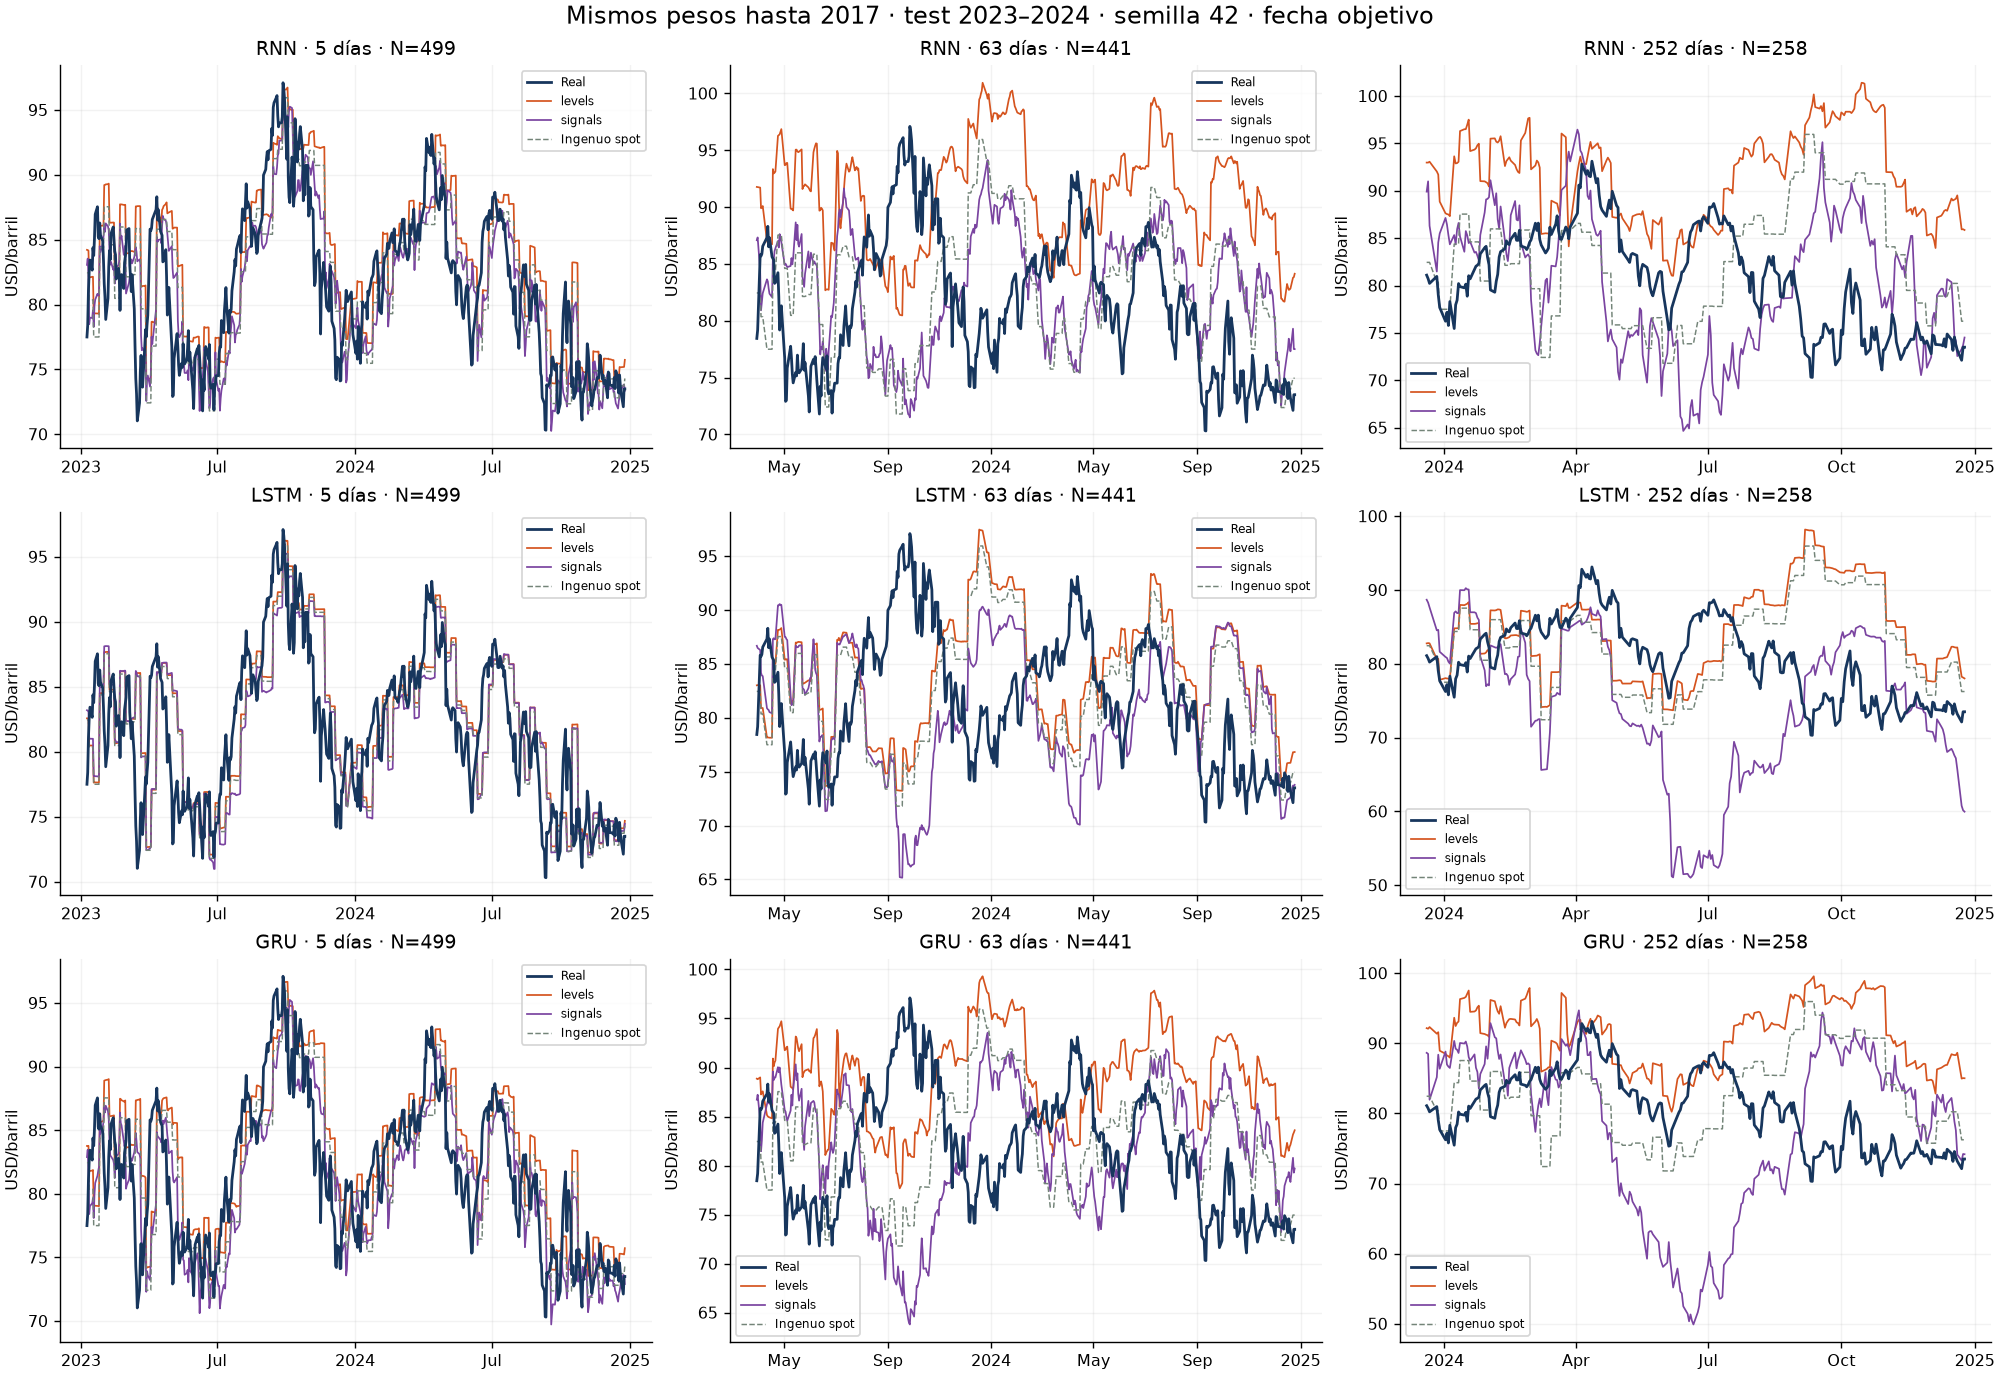

In [2]:
display(Image(filename=str(REPORT / '01_comparacion_completa.png')))

## Validación frente a test

Se mantienen los pesos y las escalas ajustados hasta 2017. La época se eligió con validación 2018–2022; no se reajusta nada con el test.

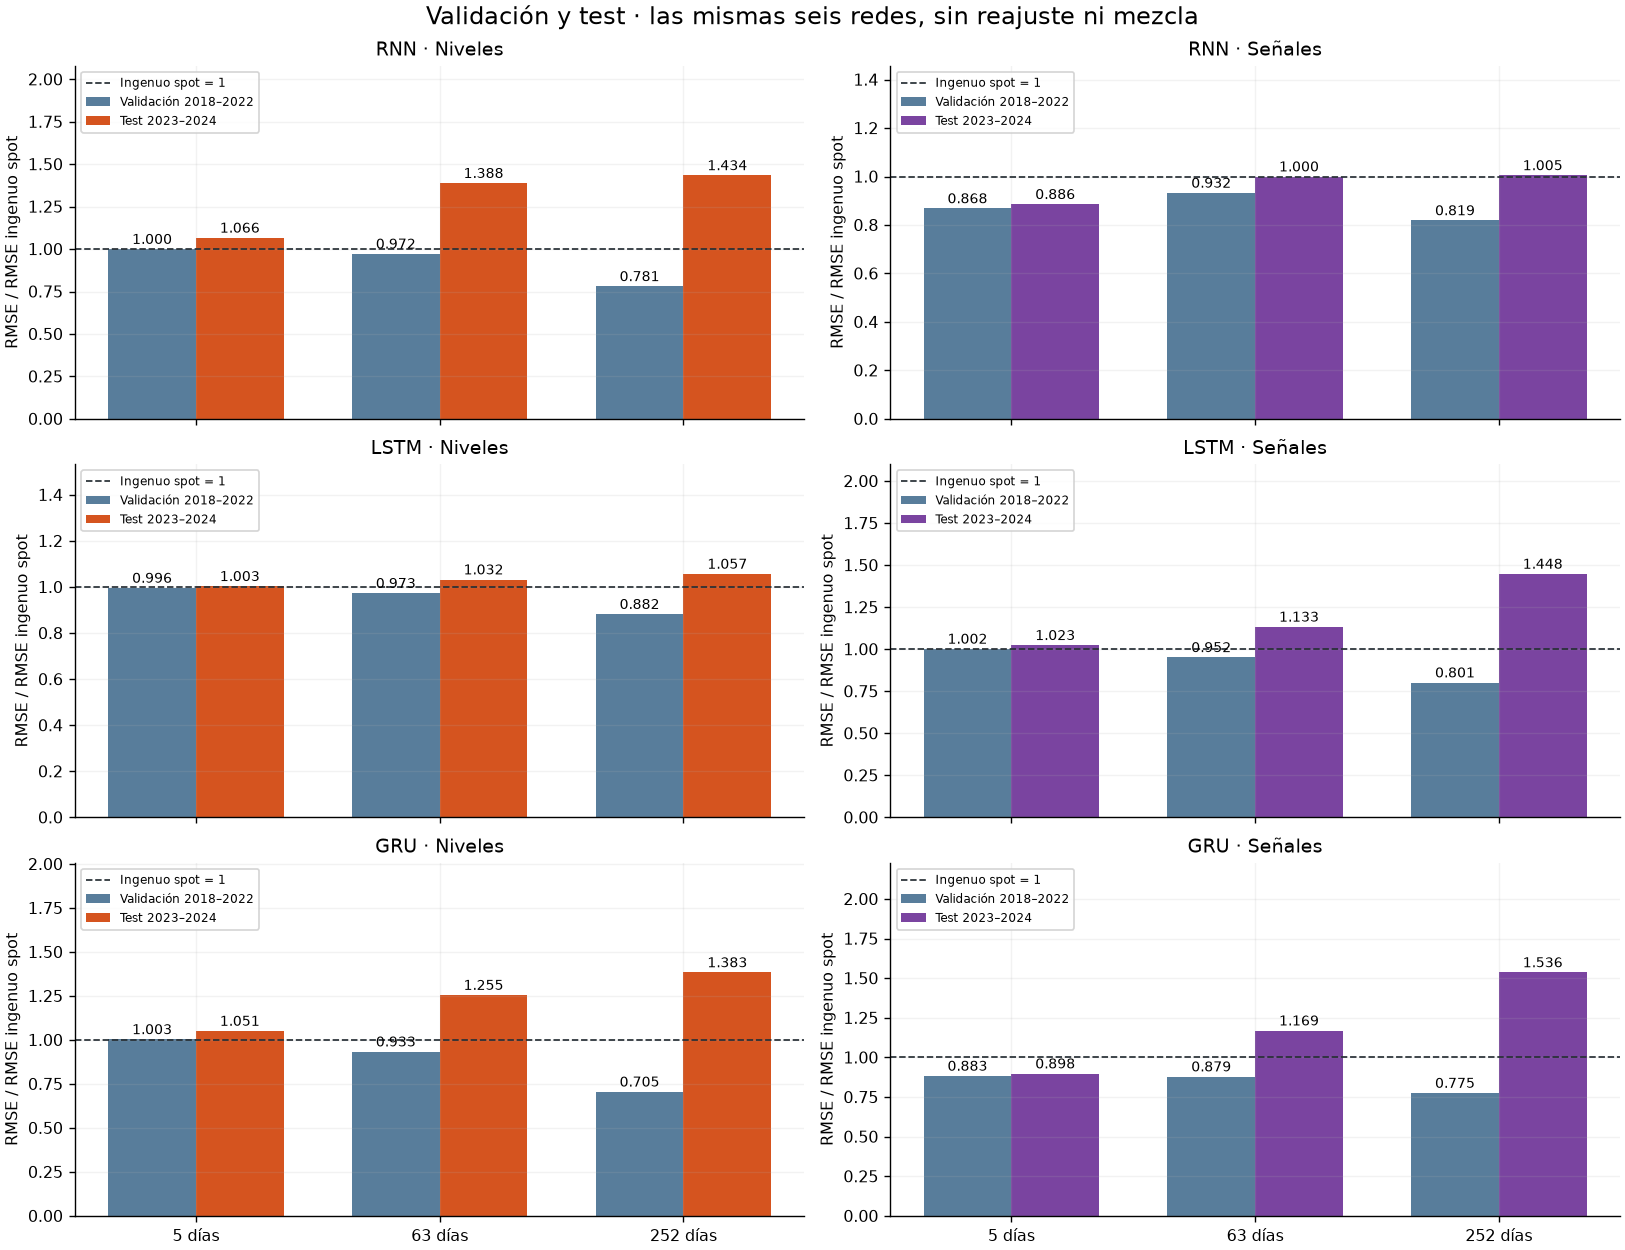

In [3]:
display(Image(filename=str(REPORT / '02_validacion_vs_test.png')))

## Diagnóstico de errores

La diagonal indica coincidencia con el real. Los puntos a 252 días están muy solapados; no representan años independientes. Los errores extremos permanecen en la evaluación.

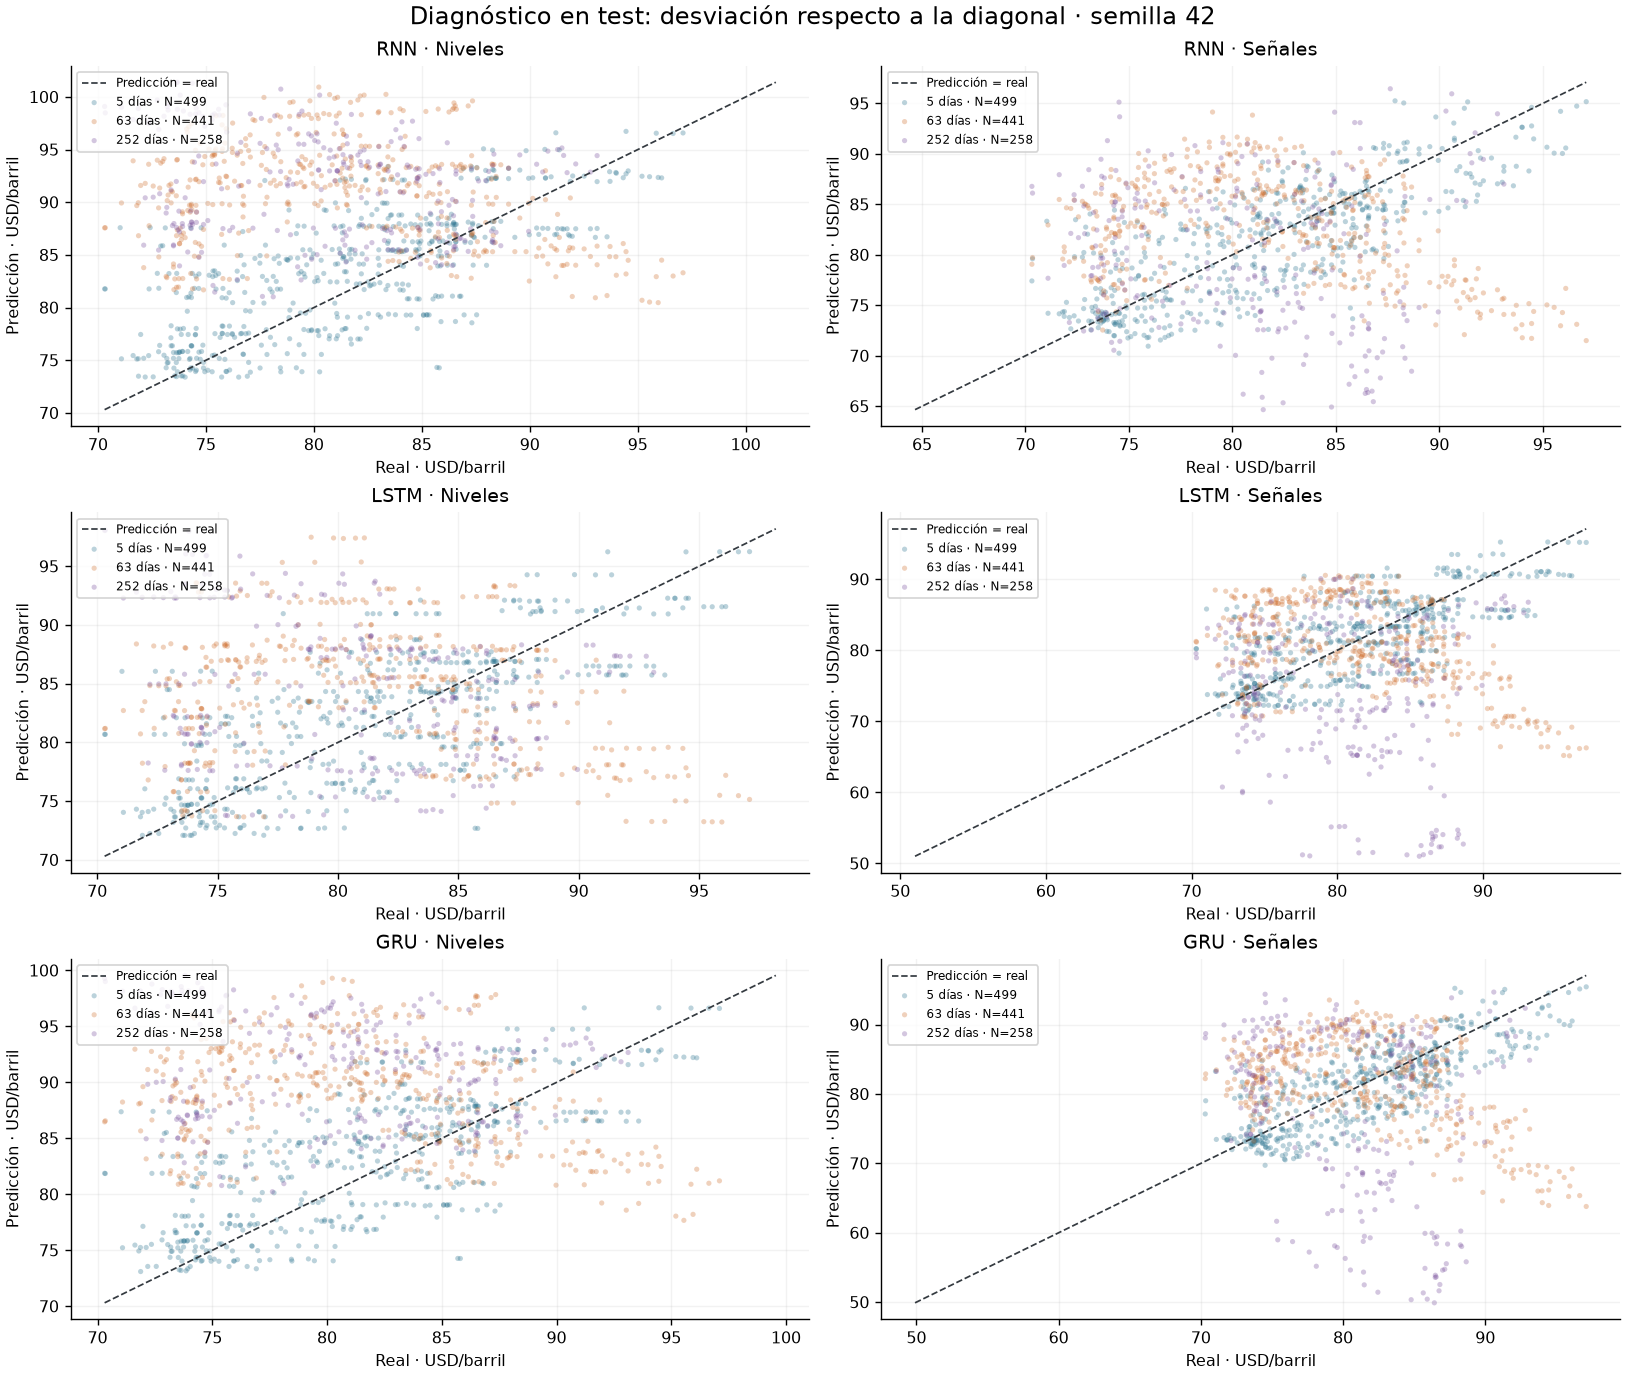

In [4]:
display(Image(filename=str(REPORT / '03_diagnostico.png')))

Las bandas son empíricas, calculadas con residuos de la validación usada en selección; no garantizan cobertura futura. Consulta las métricas por año, régimen y cobertura en el [informe completo](../experiments/recovered_fixed_test_20261120/report/INFORME.md) y en la [versión HTML](../experiments/recovered_fixed_test_20261120/report/comparacion.html).